# 🔬 Pelican-VLA 0.5: Interactive Cycle Inspector
### Session: `20261015T162257+0700_797af814`

Notebook này là công cụ tra cứu tương tác cho từng chu kỳ infer:
- Duyệt qua bất kỳ cycle nào từ `0` đến `95`.
- Xem ảnh đồng thời 3 camera (`cam_head`, `cam_left_wrist`, `cam_right_wrist`) tại thời điểm infer.
- Xem trạng thái 16 khớp robot tại chu kỳ đó.
- Vẽ đồ thị chùm 50 bước hành động tương lai (`predicted action chunk: 50x16`).
- Hiển thị Attention Overlay nếu cycle đó đã được giải thích.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

REPO_ROOT = Path('/home/anhnb9/Documents/Pelican-VLA05')
SESSION_DIR = REPO_ROOT / 'logs/sessions/20261015T162257+0700_797af814'
EXPLANATION_DIR = REPO_ROOT / 'explanations/20261015T162257+0700_797af814'

JOINT_NAMES = [
    'L_J0', 'L_J1', 'L_J2', 'L_J3', 'L_J4', 'L_J5', 'L_J6',
    'R_J0', 'R_J1', 'R_J2', 'R_J3', 'R_J4', 'R_J5', 'R_J6',
    'L_Grip', 'R_Grip'
]

meta = json.loads((SESSION_DIR / 'session.json').read_text())
camera_map = meta['camera_map']

## Hàm tra cứu chi tiết một Cycle bất kỳ

In [2]:
def inspect_cycle(cycle_num):
    name = f'cycle_{cycle_num:06d}'
    npz_path = SESSION_DIR / 'cycles' / f'{name}.npz'
    json_path = SESSION_DIR / 'cycles' / f'{name}.json'
    
    if not npz_path.exists():
        print(f"❌ Không tìm thấy cycle {cycle_num} ({npz_path.name})")
        return
        
    cycle_meta = json.loads(json_path.read_text())
    data = np.load(npz_path)
    
    state = data['state'] # (16,)
    actions = data['actions'] # (50, 16)
    
    print(f"==================================================")
    print(f" 🎯 CYCLE {cycle_num} REPORT")
    print(f"==================================================")
    print(f"• Latency: {cycle_meta.get('latency', 0):.3f}s")
    print(f"• Task: {cycle_meta.get('task', 'N/A')}")
    print(f"• Input Ages: cam_head={cycle_meta.get('input_ages', {}).get('camera:cam_head', 0)*1000:.1f}ms | "
          f"left_arm={cycle_meta.get('input_ages', {}).get('state:left_arm', 0)*1000:.1f}ms")
    print(f"• State (16-D):\n  Left Arm: {np.round(state[0:7], 3)}\n  Right Arm: {np.round(state[7:14], 3)}\n  Grippers: [L={state[14]:.1f}, R={state[15]:.1f}]")
    
    # 1. Vẽ 3 Camera RGB
    cams = ['cam_head', 'cam_left_wrist', 'cam_right_wrist']
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=110)
    fig.suptitle(f"Cycle {cycle_num} Observations (Current Frame)", fontsize=13, fontweight='bold')
    
    for idx, cam in enumerate(cams):
        key = f'history_{cam}'
        if key in data:
            # Lấy frame mới nhất trong history
            img = data[key][-1]
            axes[idx].imshow(img)
            axes[idx].set_title(cam, fontsize=11, fontweight='semibold')
            axes[idx].axis('off')
        else:
            axes[idx].text(0.5, 0.5, f"No image for {cam}", ha='center')
    plt.tight_layout()
    plt.show()
    
    # 2. Vẽ 50 Action Steps dự đoán cho 16 khớp
    fig, axes = plt.subplots(2, 1, figsize=(15, 6), sharex=True, dpi=110)
    fig.suptitle(f"Cycle {cycle_num}: Predicted 50-Step Action Trajectory Fan", fontsize=13, fontweight='bold')
    
    steps = np.arange(actions.shape[0])
    
    # Left Arm
    for j in range(7):
        axes[0].plot(steps, actions[:, j], label=JOINT_NAMES[j])
    axes[0].set_title("Left Arm Predicted Trajectory (7 Joints)", fontsize=11)
    axes[0].set_ylabel("Joint Position (rad)")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='upper right', ncol=7, fontsize=8)
    
    # Right Arm
    for j in range(7, 14):
        axes[1].plot(steps, actions[:, j], label=JOINT_NAMES[j])
    axes[1].set_title("Right Arm Predicted Trajectory (7 Joints)", fontsize=11)
    axes[1].set_ylabel("Joint Position (rad)")
    axes[1].set_xlabel("Prediction Step (0..49)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(loc='upper right', ncol=7, fontsize=8)
    
    plt.tight_layout()
    plt.show()
    
    # 3. Kiểm tra xem có attention explanation tương ứng không
    expl_dir = EXPLANATION_DIR / f'cycle_{cycle_num:06d}_rollout_step0_dim0'
    if expl_dir.exists():
        print(f"✨ Tìm thấy Attention Explanation cho Cycle {cycle_num}:")
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=110)
        fig.suptitle(f"Cycle {cycle_num} Attention Overlay", fontsize=13, fontweight='bold')
        for idx, cam in enumerate(cams):
            png = expl_dir / f'{cam}.png'
            if png.exists():
                axes[idx].imshow(Image.open(png))
                axes[idx].set_title(f"Attention: {cam}", fontsize=11)
                axes[idx].axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print(f"ℹ️ Chưa có Attention Overlay cho cycle {cycle_num}. Có thể sinh bằng Notebook 01 hoặc scripts/explain_session.py.")

## Tra cứu thử một số chu kỳ quan trọng
Hãy thử nhập số chu kỳ bất kỳ (`0..95`) vào hàm `inspect_cycle()`:
- `0`: Chu kỳ đầu tiên bắt đầu hành động.
- `3`: Chu kỳ ổn định đã có attention explanation.
- `15`: Chu kỳ nhảy khớp cánh tay cao nhất (`raw_arm_jump=0.145rad`).
- `50`: Chu kỳ giữa quá trình thực hiện nhiệm vụ rót/phục vụ cà phê.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


 🎯 CYCLE 3 REPORT
• Latency: 0.480s
• Task: serving brewed coffee
• Input Ages: cam_head=12.2ms | left_arm=1.5ms
• State (16-D):
  Left Arm: [ 0.04   0.002 -1.402  1.497 -0.371  0.081  0.062]
  Right Arm: [-0.147 -0.012  1.383  1.66   0.309  0.101 -0.105]
  Grippers: [L=1.3, R=1.3]


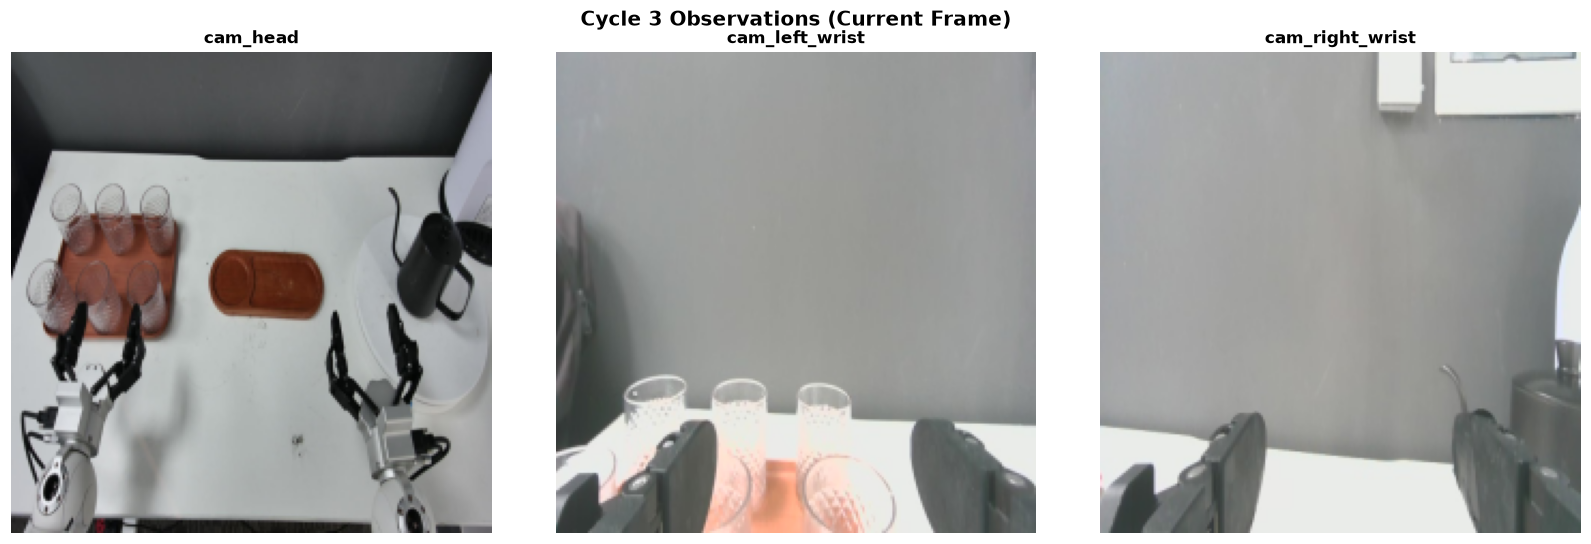

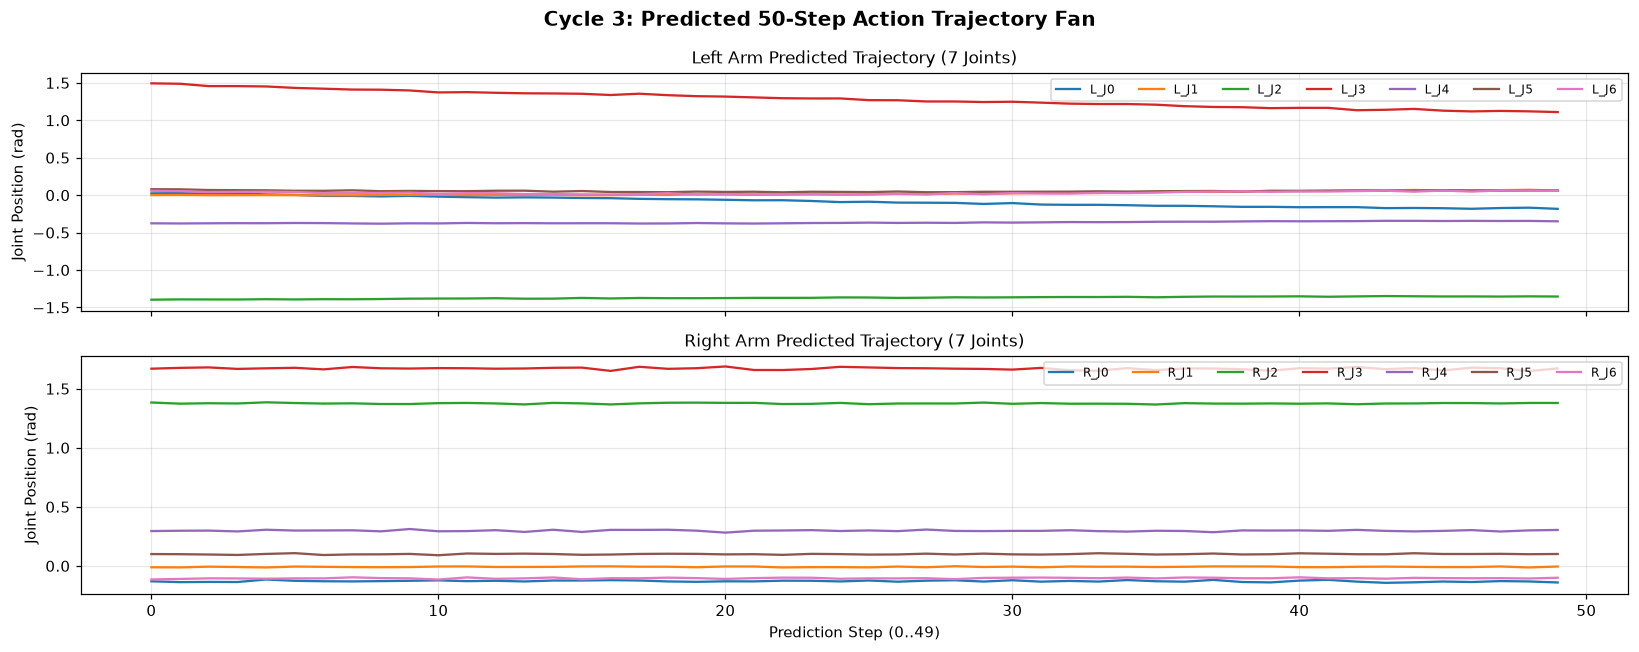

✨ Tìm thấy Attention Explanation cho Cycle 3:


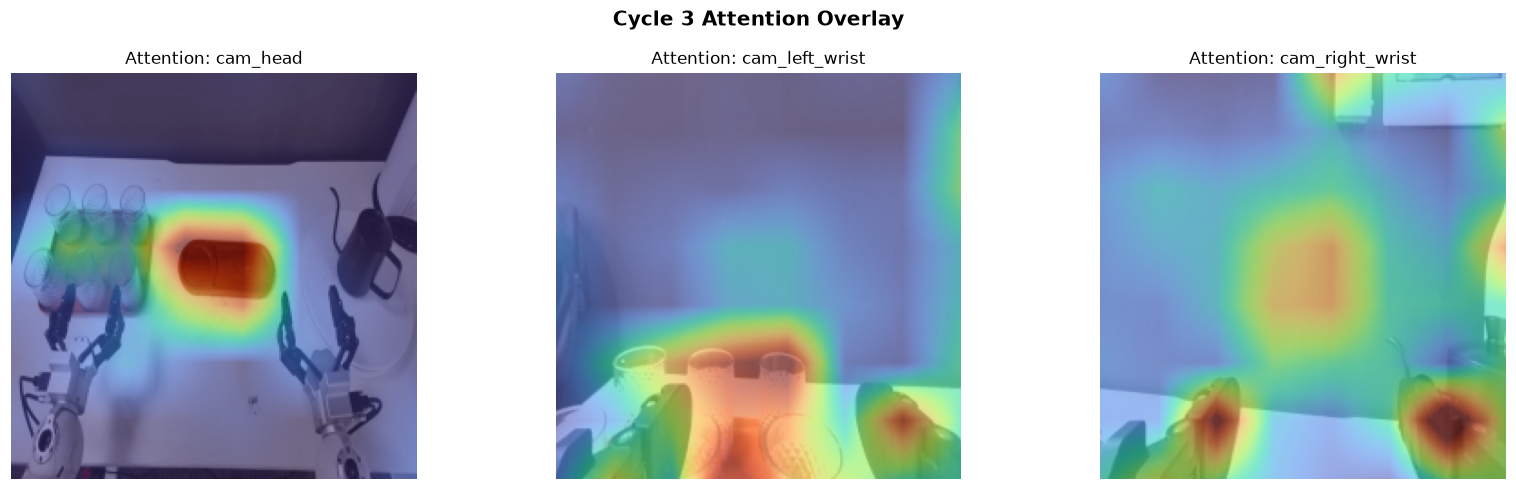

In [3]:
# Xem cycle 3 (đã có attention)
inspect_cycle(3)

 🎯 CYCLE 15 REPORT
• Latency: 0.533s
• Task: serving brewed coffee
• Input Ages: cam_head=24.6ms | left_arm=2.7ms
• State (16-D):
  Left Arm: [-0.337  0.037 -1.258  1.12  -0.473  0.134 -0.389]
  Right Arm: [-0.163  0.046  1.306  1.727  0.233  0.057 -0.16 ]
  Grippers: [L=1.3, R=1.7]


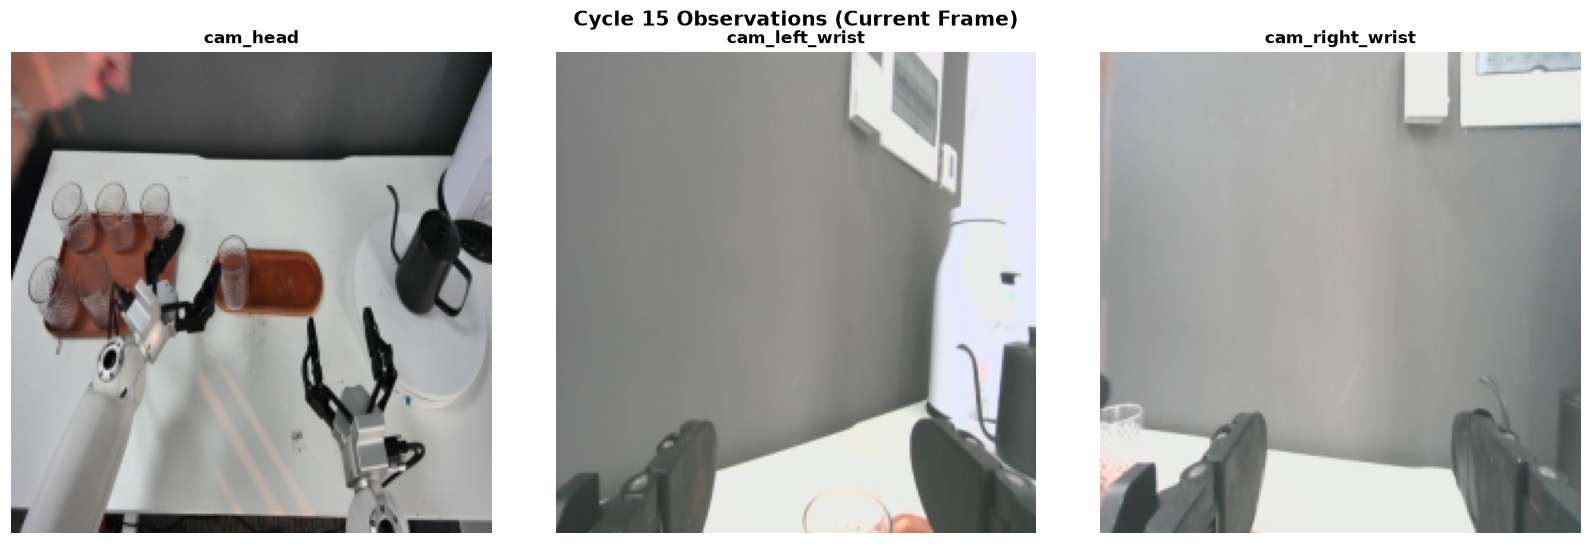

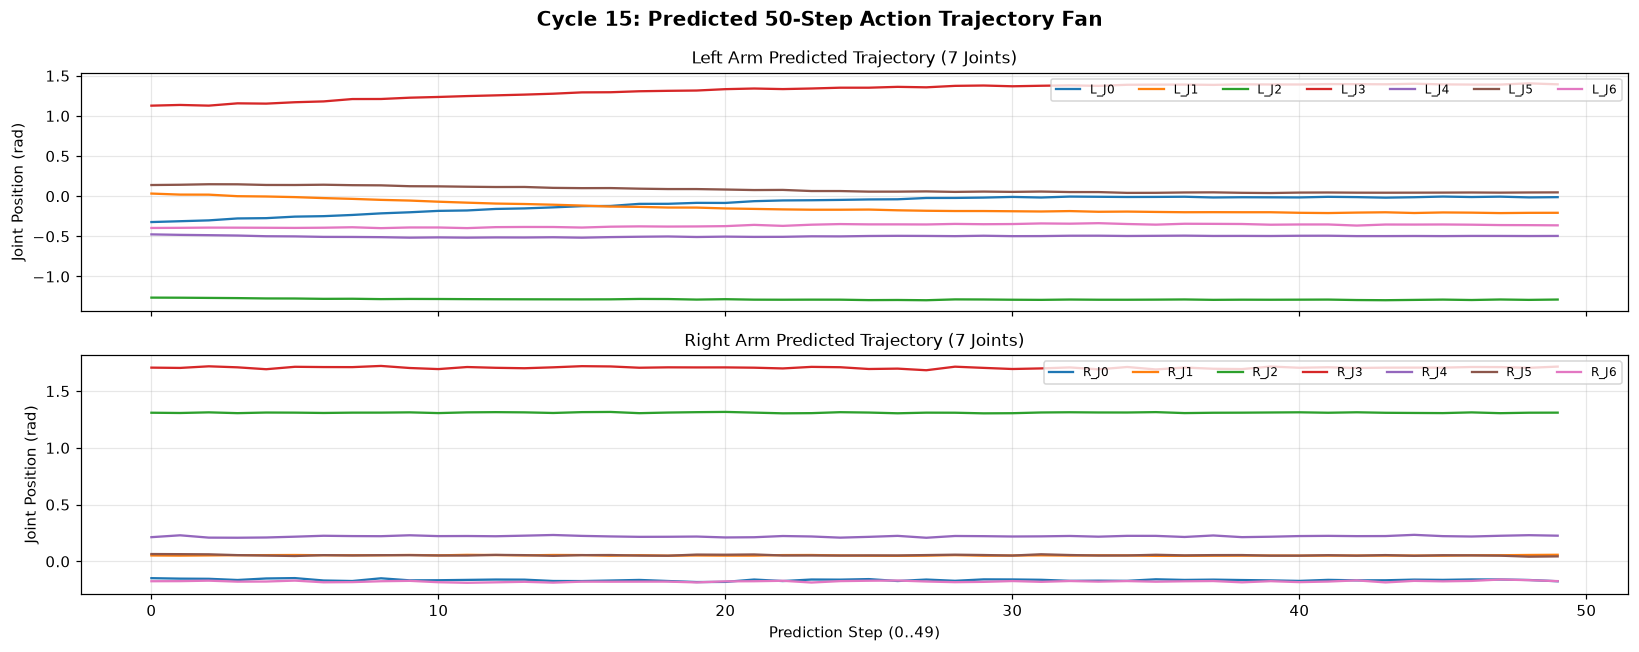

✨ Tìm thấy Attention Explanation cho Cycle 15:


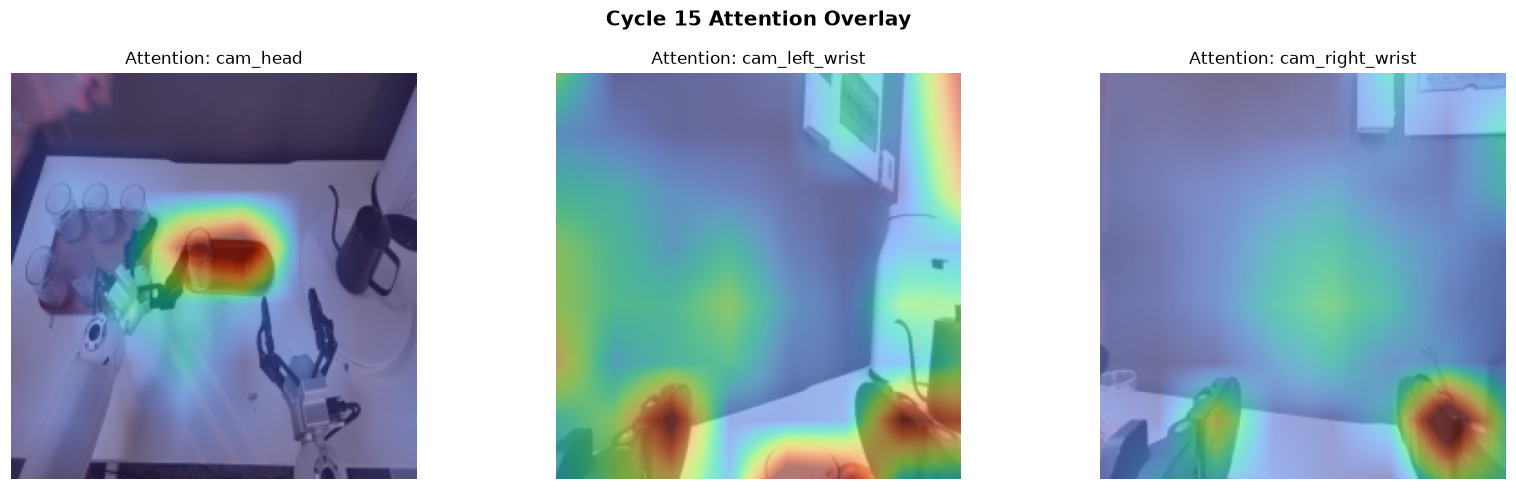

In [4]:
# Xem cycle 15 (thời điểm nhảy khớp cao nhất)
inspect_cycle(15)

 🎯 CYCLE 50 REPORT
• Latency: 0.412s
• Task: serving brewed coffee
• Input Ages: cam_head=33.5ms | left_arm=9.2ms
• State (16-D):
  Left Arm: [ 0.028 -0.141 -1.287  1.495 -0.486  0.033 -0.186]
  Right Arm: [ 0.037  0.221  1.396  1.43   0.243  0.076 -0.427]
  Grippers: [L=1.3, R=2.7]


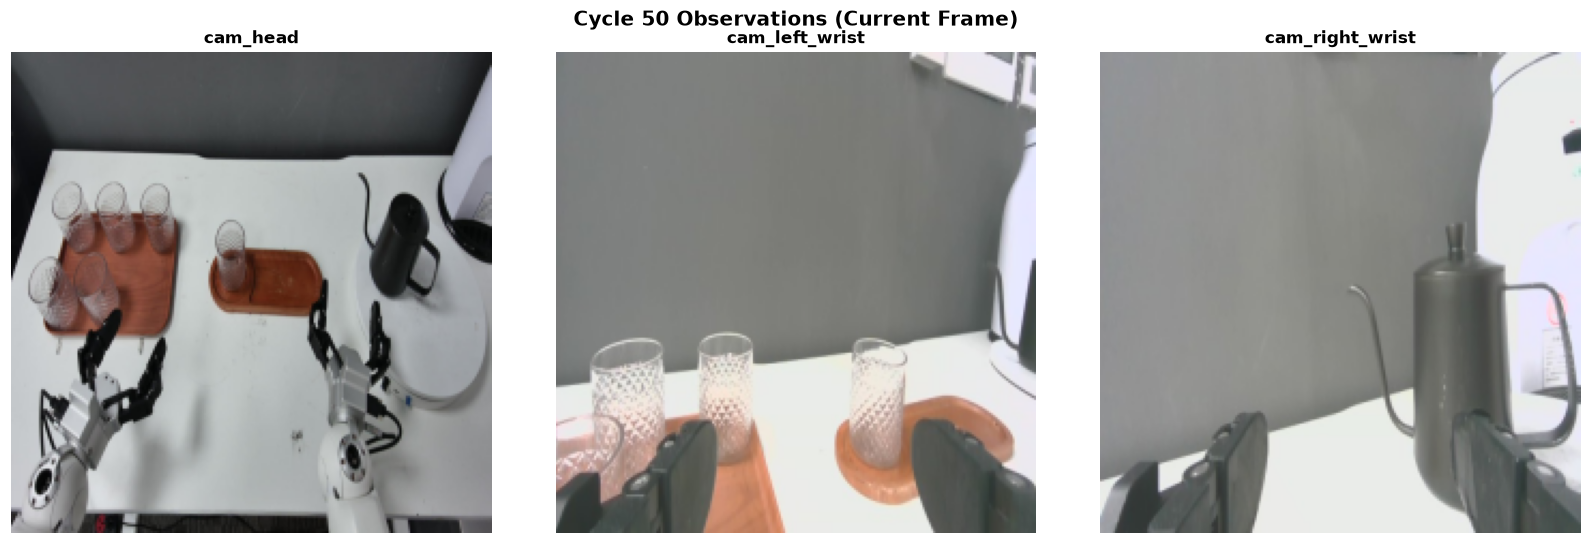

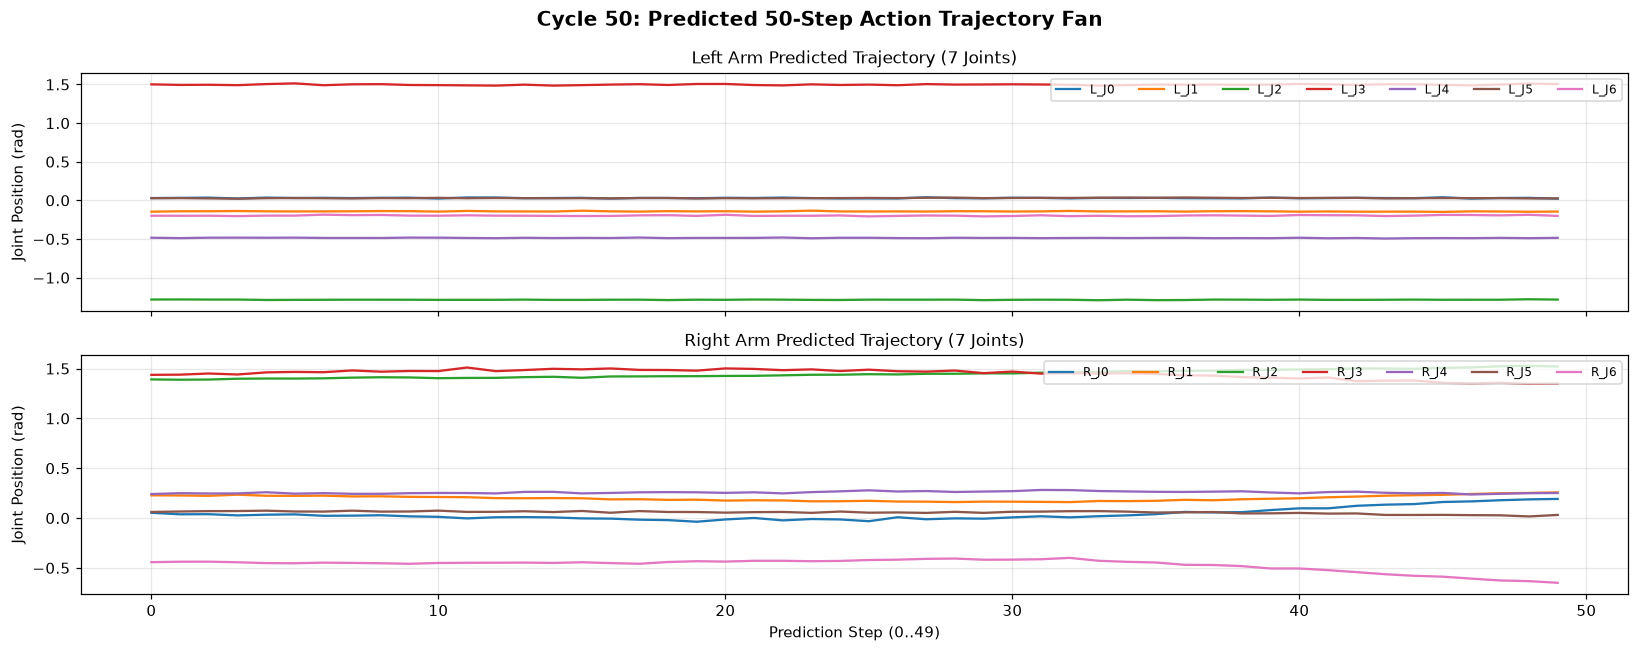

ℹ️ Chưa có Attention Overlay cho cycle 50. Có thể sinh bằng Notebook 01 hoặc scripts/explain_session.py.


In [5]:
# Xem cycle 50 (giữa phiên làm việc)
inspect_cycle(50)